# Prediction - regression and classification

Line:

%matplotlib inline

allows you to display charts without using plt.show()

In [225]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np

## Linear Regression
This method assumes that the relationship between the explained and the explanatory variable is linear, i.e. we are trying to find the function:

y = a * x + b

that best describes the points from the set, where:

- y - explained variable,
- x - explanatory variable,
- a - slope coefficient,
- b - intercept.

For the regression example, we will use generated points randomly spaced from the line with slope coefficient a = 2 and intercept b = -3.

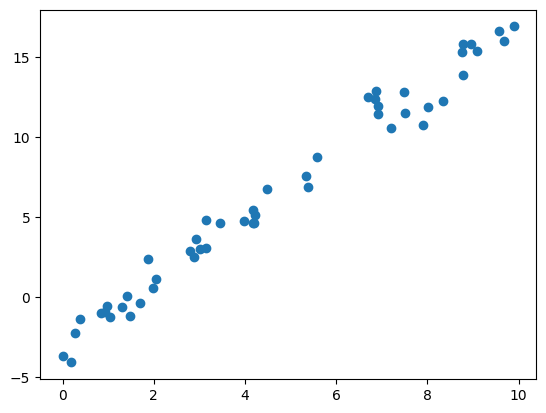

In [226]:
rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = 2 * x - 3 + rng.randn(50)
plt.scatter(x, y);

We import the model for linear regression from the scikit-learn package (sklearn) and create the appropriate object. When creating an object, we can set values for the model's hyperparameters. One of such parameters is *fit_intercept*, which indicates whether the model should determine the value for the intercept **b**.

In [227]:
from sklearn.linear_model import LinearRegression
model = LinearRegression(fit_intercept=True)
model

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


The explanatory data should have dimension $<$number of samples$>$ x $<$number of dimensions/features$>$, so we need to change the dimensions for **x**.

In [228]:
X = x[:, np.newaxis]
X.shape

(50, 1)

We train the model on the data. We can view the determined values for model parameters **a** and **b**.

In [229]:
model.fit(X, y)
# a
model.coef_ 

array([2.02720881])

In [230]:
#b
model.intercept_ 

np.float64(-2.9985770855532037)

And the accuracy of the model.

In [231]:
model.score(X, y)

0.9790800609430612

Applying the designated linear regression model to "new" data.

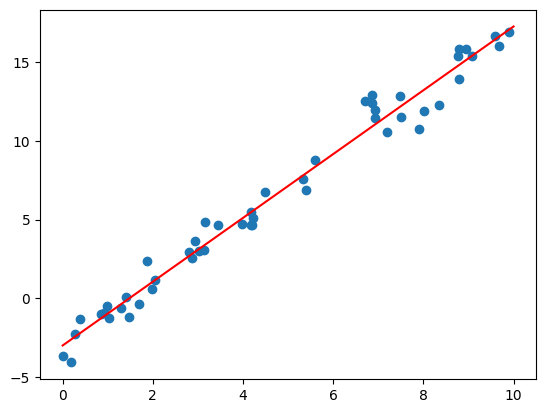

In [232]:
xfit = np.linspace(0, 10, 1000)
yfit = model.predict(xfit[:, np.newaxis])

# Visualization of results
plt.scatter(x, y)
plt.plot(xfit, yfit,'-r')

### Task 1. (0.5 points)
> Using a phone company's data (churn.txt) and a linear regression model, determine an exact per-minute night rate.

In [233]:
import pandas as pd
from sklearn.linear_model import LinearRegression
data = pd.read_csv("churn.txt")

X = data[["Night Mins"]]
y = data["Night Charge"]
model = LinearRegression()
model.fit(X, y)

night_rate = model.coef_[0]
night_rate

np.float64(0.045000947825913344)

We are looking for the relationship between body weight and brain weight for mammals in the form of a function:

y = a * x,

where *x* means brain weight and *y* means body weight.

We load the appropriate file.

In [234]:
import pandas as pd

df = pd.read_csv('brain_body.csv', index_col='Index')
df.head()

,BrainWeight,BodyWeight
Index,,
1,3.385,44.5
2,0.480,15.5
3,1.350,8.1
4,465.000,423.0
5,36.330,119.5


### Task 2. (0.5 points)
> Investigate whether there is a correlation between the variables under study.

In [235]:
correlation = df['BodyWeight'].corr(df['BrainWeight'])
correlation

np.float64(0.9341638423233545)

### Task 2 - answer
There is a positive correlation of 0.93 (Pearson coefficient).

### Task 3. (0.5 points)
> Create a linear regression model object suitable for the dependencies in the above problem.
>
> Prepare the explanatory variable (name it *X*) and the explained variable (name it *y*) appropriately.

In [ ]:
model = LinearRegression()

X = df[['BrainWeight']]
y = df['BodyWeight']
X.head(), y.head()

(       BrainWeight
 Index             
 1            3.385
 2            0.480
 3            1.350
 4          465.000
 5           36.330,
 Index
 1     44.5
 2     15.5
 3      8.1
 4    423.0
 5    119.5
 Name: BodyWeight, dtype: float64)

We divide the dataset into test and training sets.

In [237]:
from sklearn.model_selection import train_test_split

X1, X2, y1, y2 = train_test_split(X, y, random_state=0,
                                  train_size=0.6)
print ('Size of training set = %d and test set = %d' % (y1.size, y2.size))

Size of training set = 37 and test set = 25


We train and evaluate the model using mean squared error.

In [238]:
from sklearn.metrics import mean_squared_error

model.fit(X1, y1)
y2_model = model.predict(X2)

mean_squared_error(y2, y2_model)

1490805.6876027263

Visualization of results.

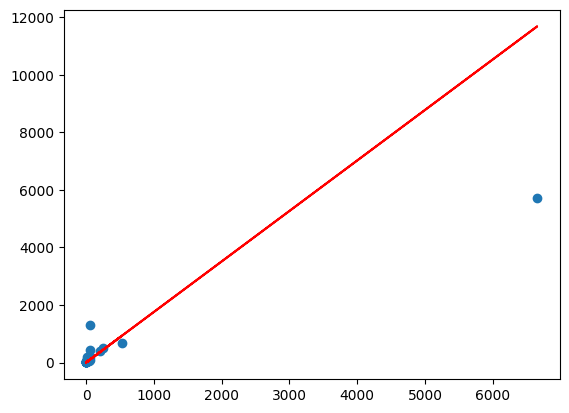

In [239]:
plt.scatter(X2, y2)
plt.plot(X2, y2_model,'-r')

### Task 4. (1.5 points)
> Change a scale of the analyzed data set to log scale and repeat the regression. Compare the results. Also compare the accuracy of the model on training and test data.

MSE (normal): 1490805.6876027263
MSE (log): 0.6033173216419351
Coefficient (original):  1.7544998769921127
Coefficient (log):  0.7489249147778116
Accuracy comparison:
R^2 (test, original): -0.1764457049209467
R^2 (training, log): 0.9377420712877779
R^2 (test, log): 0.8883475436690766


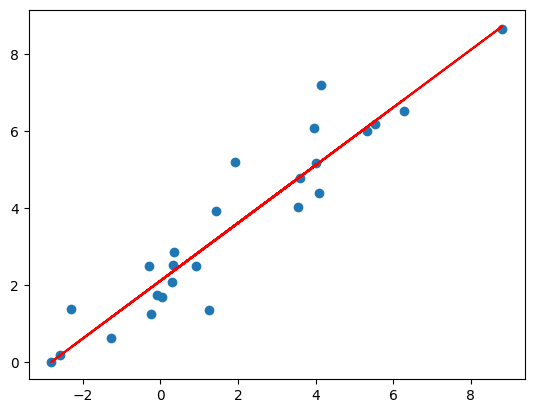

In [ ]:
from sklearn.metrics import mean_squared_error, r2_score

mse_orig = mean_squared_error(y2, y2_model)
coef_orig = model.coef_[0]
r2_test_orig = r2_score(y2, y2_model)

X_log = np.log(df[['BrainWeight']])
y_log = np.log(df['BodyWeight'])
X1_log, X2_log, y1_log, y2_log = train_test_split(X_log, y_log, random_state=0, train_size=0.6)

model_log = LinearRegression()
model_log.fit(X1_log, y1_log)

y2_model_log = model_log.predict(X2_log)


r2_train_log = model_log.score(X1_log, y1_log) # Accuracy on TRAINING data
r2_test_log = r2_score(y2_log, y2_model_log)   # Accuracy on TEST data
mse_log = mean_squared_error(y2_log, y2_model_log)
coef_log = model_log.coef_[0]

print("MSE (normal):", mean_squared_error(y2, y2_model))
print("MSE (log):", mse_log)

print("Coefficient (original): ", coef_orig)
print("Coefficient (log): ", coef_log)

print("Accuracy comparison:")
print("R^2 (test, original):", r2_test_orig)
print("R^2 (training, log):", r2_train_log)
print("R^2 (test, log):", r2_test_log)

plt.scatter(X2_log, y2_log)
plt.plot(X2_log, y2_model_log,'-r')


If the process consists of several stages, the *Pipeline* class can be used.

http://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

The following example defines a process consisting of data transformation (*PolynomialFeatures*) and linear regression.

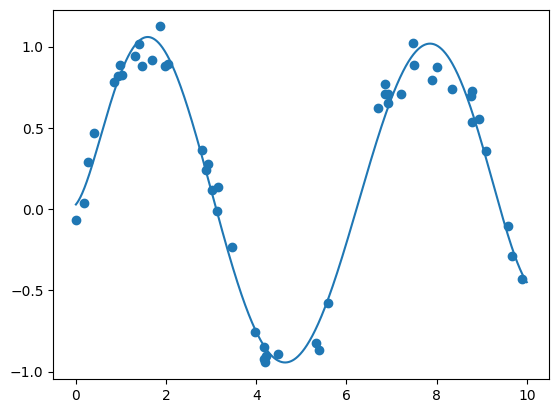

In [241]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures

poly_model = make_pipeline(PolynomialFeatures(7),
                           LinearRegression())

rng = np.random.RandomState(1)
x = 10 * rng.rand(50)
y = np.sin(x) + 0.1 * rng.randn(50)

poly_model.fit(x[:, np.newaxis], y)
yfit = poly_model.predict(xfit[:, np.newaxis])

plt.scatter(x, y)
plt.plot(xfit, yfit);

### Task 5. (0.5 points)
> Test other values (smaller and larger than the example) as an argument when creating an object of the *PolynomialFeatures* class. What can you say about the model's behavior?

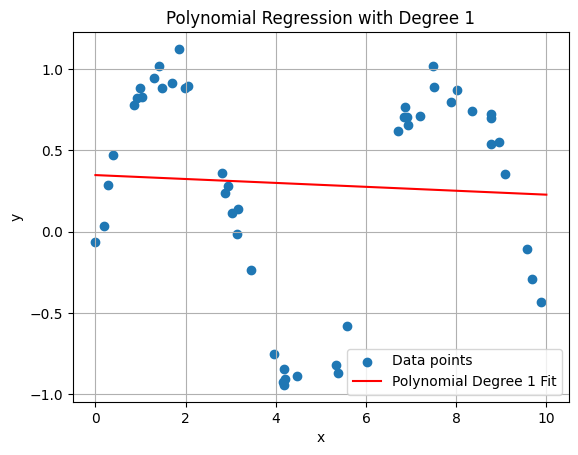

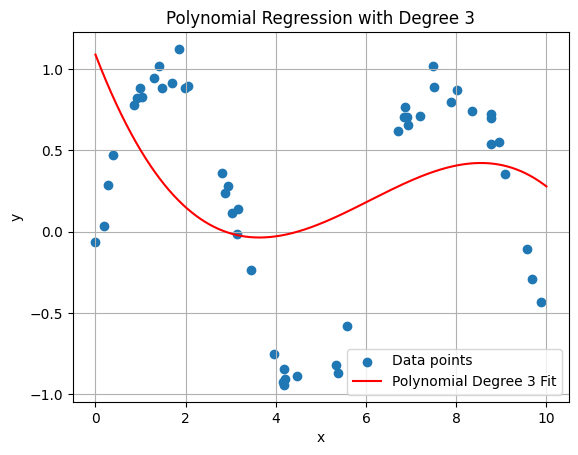

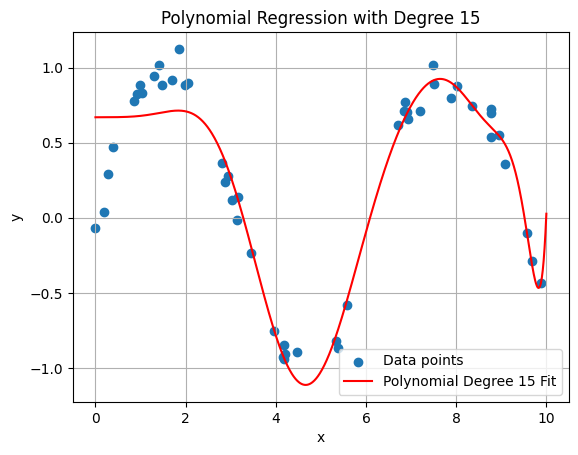

In [242]:
def plot_polynomial_fit(degree):
    poly_model = make_pipeline(PolynomialFeatures(degree), LinearRegression())

    poly_model.fit(x[:, np.newaxis], y)

    yfit = poly_model.predict(xfit[:, np.newaxis])

    plt.figure()
    plt.scatter(x, y, label='Data points')
    plt.plot(xfit, yfit, color='red', label=f'Polynomial Degree {degree} Fit')
    plt.title(f'Polynomial Regression with Degree {degree}')
    plt.xlabel('x')
    plt.ylabel('y')
    plt.legend()
    plt.grid(True)
    plt.show()

plot_polynomial_fit(1)
plot_polynomial_fit(3)

plot_polynomial_fit(15)

### Answer to Task 5
**Degree 1**: The model fit is a straight line and it underfits the data.  
**Degree 3**: The model fit is a slightly curved line but it still underfits the data.  
**Degree 7** (your example): The model fit is good.  
**Degree 15**: The model fit is a passes too closely to the point so it overfits the data (I don't know why it breaks on the left side of the graph). 

### Task 6. (1.5 points)
> For the above random data, test the regression with $L_2$ regularization and $L_1$ regularization. Draw a graph and calculate the mean squared and mean absolute errors for the three models. Compare the results.
>
> **NOTE:** Both model error measures are available in the *sklearn.metrics* module.

http://scikit-learn.org/stable/modules/classes.html#module-sklearn.metrics

/home/polemaster/Downloads/prediction/ADM_prediction/venv/lib/python3.13/site-packages/sklearn/linear_model/_coordinate_descent.py:695: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 2.017e+00, tolerance: 2.065e-03
  model = cd_fast.enet_coordinate_descent(


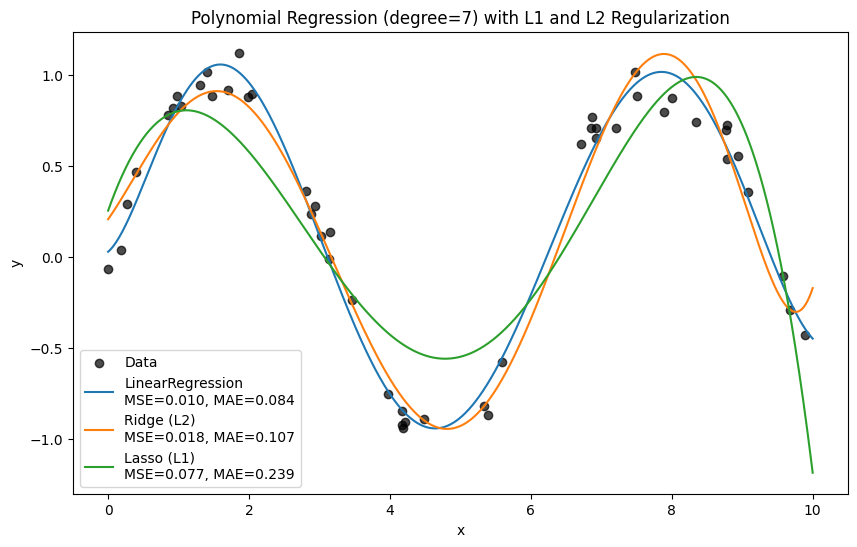

LinearRegression     | MSE = 0.0099 | MAE = 0.0838
Ridge (L2)           | MSE = 0.0181 | MAE = 0.1070
Lasso (L1)           | MSE = 0.0771 | MAE = 0.2389


In [ ]:
from sklearn.linear_model import Ridge # L2
from sklearn.linear_model import Lasso # L1
from sklearn.metrics import mean_absolute_error

degree = 7
models = {
    "LinearRegression": make_pipeline(PolynomialFeatures(degree), LinearRegression()),
    "Ridge (L2)": make_pipeline(PolynomialFeatures(degree), Ridge(alpha=1.0)),
    "Lasso (L1)": make_pipeline(PolynomialFeatures(degree), Lasso(alpha=0.001, max_iter=10000))
}

results = {}
for name, model in models.items():
    model.fit(x[:, np.newaxis], y)
    yfit = model.predict(xfit[:, np.newaxis])
    ypred = model.predict(x[:, np.newaxis])

    mse = mean_squared_error(y, ypred)
    mae = mean_absolute_error(y, ypred)
    results[name] = (mse, mae, yfit)


plt.figure(figsize=(10, 6))
plt.scatter(x, y, color="black", label="Data", alpha=0.7)

for name, (mse, mae, yfit) in results.items():
    plt.plot(xfit, yfit, label=f"{name}\nMSE={mse:.3f}, MAE={mae:.3f}")

plt.xlabel("x")
plt.ylabel("y")
plt.title("Polynomial Regression (degree=7) with L1 and L2 Regularization")
plt.legend()
plt.show()


for name, (mse, mae, _) in results.items():
    print(f"{name:20s} | MSE = {mse:.4f} | MAE = {mae:.4f}")

### Linear regression as a function of two variables

In [244]:
df = pd.read_csv("boston_data.csv")
df.head()

,Unnamed: 0,CRIM,ZN,INDUS,CHAS,NOX,RM,AGE,DIS,RAD,TAX,PTRATIO,B,LSTAT,MEDV
0,0,0.00632,18.0,2.31,0.0,0.538,6.575,65.2,4.0900,1.0,296.0,15.3,396.90,4.98,24.0
1,1,0.02731,0.0,7.07,0.0,0.469,6.421,78.9,4.9671,2.0,242.0,17.8,396.90,9.14,21.6
2,2,0.02729,0.0,7.07,0.0,0.469,7.185,61.1,4.9671,2.0,242.0,17.8,392.83,4.03,34.7
3,3,0.03237,0.0,2.18,0.0,0.458,6.998,45.8,6.0622,3.0,222.0,18.7,394.63,2.94,33.4
4,4,0.06905,0.0,2.18,0.0,0.458,7.147,54.2,6.0622,3.0,222.0,18.7,396.90,5.33,36.2


In [245]:
X = pd.DataFrame(df.iloc[:,:-1])
y = pd.DataFrame(df.iloc[:,-1])

In [246]:
X1, X2, y1, y2 = train_test_split(X, y, random_state=0,
                                  train_size=0.8)

In [247]:
x_train = X1[['RM', 'LSTAT']].values.reshape(-1,2)
x_test = X2[['RM', 'LSTAT']].values.reshape(-1,2)
model = LinearRegression(fit_intercept=False)
model.fit(x_train,y1)
y2_model = model.predict(x_test)
mean_squared_error(y2, y2_model)

37.39966159556811

#### Task 7. (2.5 points)
> Load the *winequality-red.csv* file and divide it into training and testing sets in the ratio of 4:1. Research the correlation between available attributes and wine quality and select several (min. 3) to create a model. If necessary, use a polynomial model. Use the $L_2$ regularization and examine the mean squared and absolute mean errors as well as the coefficient of determination. Compare the results.
>
> **NOTE:** The coefficient of determination is available in the sklearn.metrics module.

In [248]:
df = pd.read_csv("winequality-red.csv", sep=';')

print("Data shape:", df.shape)
df.head()

Data shape: (1599, 12)


,fixed acidity,volatile acidity,citric acid,residual sugar,chlorides,free sulfur dioxide,total sulfur dioxide,density,pH,sulphates,alcohol,quality
0,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5
1,7.8,0.88,0.00,2.6,0.098,25.0,67.0,0.9968,3.20,0.68,9.8,5
2,7.8,0.76,0.04,2.3,0.092,15.0,54.0,0.9970,3.26,0.65,9.8,5
3,11.2,0.28,0.56,1.9,0.075,17.0,60.0,0.9980,3.16,0.58,9.8,6
4,7.4,0.70,0.00,1.9,0.076,11.0,34.0,0.9978,3.51,0.56,9.4,5


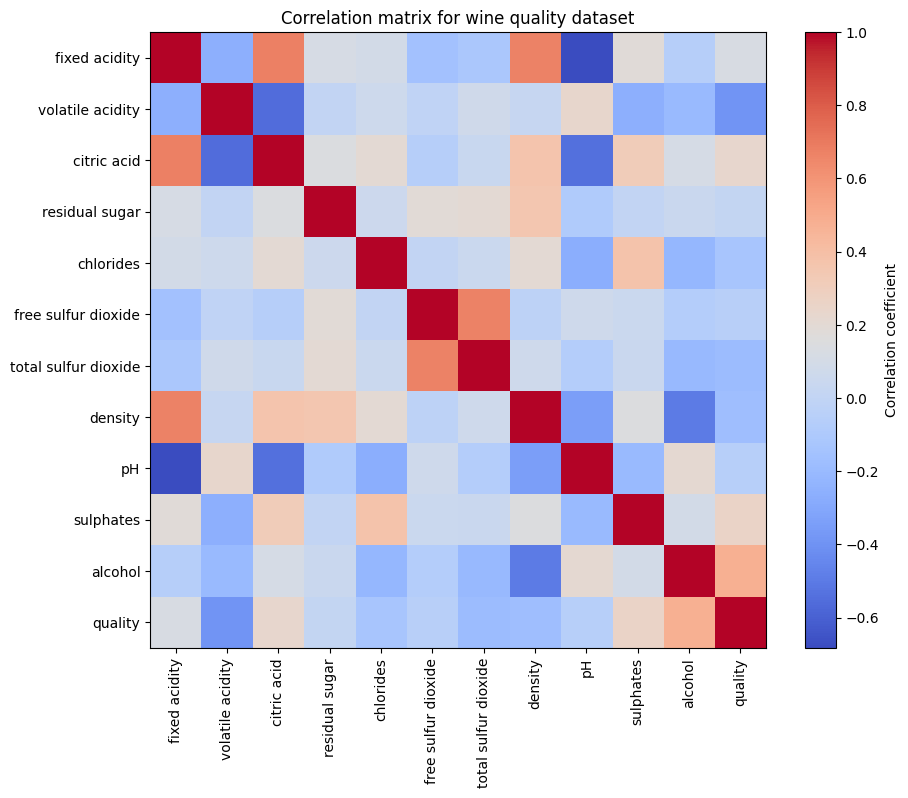

In [249]:
corr = df.corr(numeric_only=True)
plt.figure(figsize=(10, 8))
plt.imshow(corr, cmap='coolwarm', interpolation='none')
plt.colorbar(label="Correlation coefficient")
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlation matrix for wine quality dataset")
plt.show()

In [ ]:
correlation_with_quality = corr['quality'].sort_values(ascending=False)
print("Correlation with quality:\n", correlation_with_quality, "\n")

selected_features = correlation_with_quality.index[1:4].tolist()
print("Selected features:", selected_features)

X = df[selected_features]
y = df['quality']

Correlation with quality:
 quality                 1.000000
alcohol                 0.476166
sulphates               0.251397
citric acid             0.226373
fixed acidity           0.124052
residual sugar          0.013732
free sulfur dioxide    -0.050656
pH                     -0.057731
chlorides              -0.128907
density                -0.174919
total sulfur dioxide   -0.185100
volatile acidity       -0.390558
Name: quality, dtype: float64 

Selected features: ['alcohol', 'sulphates', 'citric acid']


In [251]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

ridge_model = Ridge(alpha=1.0)
ridge_model.fit(X_train, y_train)
y_pred = ridge_model.predict(X_test)

mse = mean_squared_error(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
r2 = r2_score(y_test, y_pred)

print(f"Ridge Regression Results:")
print(f"MSE = {mse:.4f}")
print(f"MAE = {mae:.4f}")
print(f"R² = {r2:.4f}")

poly_degree = 2
poly_ridge = make_pipeline(PolynomialFeatures(poly_degree), Ridge(alpha=1.0))
poly_ridge.fit(X_train, y_train)
y_poly_pred = poly_ridge.predict(X_test)

mse_poly = mean_squared_error(y_test, y_poly_pred)
mae_poly = mean_absolute_error(y_test, y_poly_pred)
r2_poly = r2_score(y_test, y_poly_pred)

print(f"\nPolynomial Ridge Regression (degree={poly_degree}) Results:")
print(f"MSE = {mse_poly:.4f}")
print(f"MAE = {mae_poly:.4f}")
print(f"R² = {r2_poly:.4f}")


Ridge Regression Results:
MSE = 0.4493
MAE = 0.5409
R² = 0.3125

Polynomial Ridge Regression (degree=2) Results:
MSE = 0.4301
MAE = 0.5258
R² = 0.3419


### Answer to task 7
The polynomial Ridge model slightly improves all metrics, showing a better fit to the data.

Its higher R² and lower errors mean that adding polynomials improves the model.

## Support Vector Machine

In [252]:
from sklearn import svm

We create sample data.

In [253]:
X = np.array([[1,2],
             [5,8],
             [1.5,1.8],
             [8,8],
             [1,0.6],
             [9,11]])
y = [0,1,0,1,0,1]

We create and teach a model.

In [254]:
clf = svm.SVC(kernel = 'linear')
clf.fit(X, y)  

,C,1.0
,kernel,'linear'
,degree,3
,gamma,'scale'
,coef0,0.0
,shrinking,True
,probability,False
,tol,0.001
,cache_size,200
,class_weight,None
,verbose,False


In [255]:
clf.score(X,y)

1.0

Classification of the new point.

In [256]:
clf.predict([[0.58,0.76]])

array([0])

In [257]:
clf.predict([[10.58,10.76]])

array([1])

[0.1380943  0.24462418]


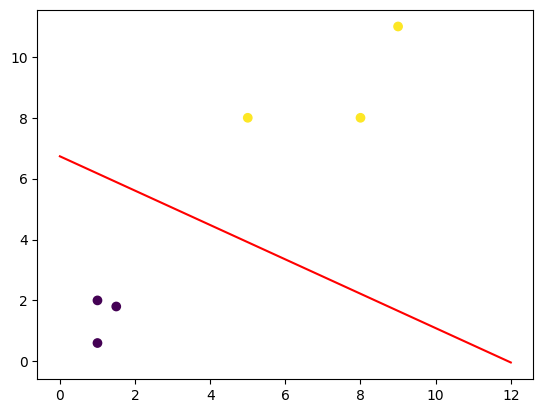

In [258]:
w = clf.coef_[0]
print(w)

a = -w[0] / w[1]

xx = np.linspace(0,12)
yy = a * xx - clf.intercept_[0] / w[1]

h0 = plt.plot(xx, yy, '-r')
plt.scatter(X[:, 0], X[:, 1], c = y)

Getting support vectors.

In [259]:
clf.support_vectors_

array([[1.5, 1.8],
       [5. , 8. ]])

Getting vectors indexes.

In [260]:
clf.support_ 

array([2, 1], dtype=int32)

Getting the number of support vectors for each class.

In [261]:
clf.n_support_ 

array([1, 1], dtype=int32)

### Task 8. (2.5 points)
> Perform classification using the SVM method on the *iris* dataset. Divide the data into training and test data in a 7:3 ratio. Test different values for *kernel* ('linear','rbf','poly','sigmoid') and *gamma* (0, 10, 100) for *kernel*='rbf'. Compare accuracy on training and test sets for different model parameters. Also check the *f1* values for the prediction results of the tested models.
>
> **NOTE:** The *f1* measure is available in the *sklearn.metrics* module.

Import of the *iris* dataset.

In [262]:
from sklearn import svm, datasets

iris = datasets.load_iris()
X = iris.data[:, :2] 
y = iris.target

In [263]:
from sklearn.metrics import accuracy_score, f1_score

iris = datasets.load_iris()
X = iris.data[:, :2]   # use first two features for visualization
y = iris.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y)

kernels = ['linear', 'poly', 'sigmoid']
gamma_values = [0.1, 10, 100]  # for 'rbf' only

results = []

In [264]:
for kernel in kernels:
    model = svm.SVC(kernel=kernel)
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test, average='weighted')

    results.append({
        "Kernel": kernel,
        "Gamma": "-",
        "Train Acc": acc_train,
        "Test Acc": acc_test,
        "F1 Score": f1
    })

In [265]:
for g in gamma_values:
    model = svm.SVC(kernel='rbf', gamma=g)
    model.fit(X_train, y_train)
    y_pred_train = model.predict(X_train)
    y_pred_test = model.predict(X_test)

    acc_train = accuracy_score(y_train, y_pred_train)
    acc_test = accuracy_score(y_test, y_pred_test)
    f1 = f1_score(y_test, y_pred_test, average='weighted')

    results.append({
        "Kernel": "rbf",
        "Gamma": g,
        "Train Acc": acc_train,
        "Test Acc": acc_test,
        "F1 Score": f1
    })

In [266]:
df_results = pd.DataFrame(results)
print(df_results)

    Kernel Gamma  Train Acc  Test Acc  F1 Score
0   linear     -   0.819048  0.711111  0.706489
1     poly     -   0.838095  0.688889  0.687500
2  sigmoid     -   0.123810  0.088889  0.069048
3      rbf   0.1   0.819048  0.733333  0.732143
4      rbf    10   0.866667  0.755556  0.755284
5      rbf   100   0.933333  0.577778  0.584417


In [267]:
best_idx = df_results['Test Acc'].idxmax()
best_kernel = df_results.loc[best_idx, 'Kernel']
best_gamma = df_results.loc[best_idx, 'Gamma']
print(f"\nBest model: kernel={best_kernel}, gamma={best_gamma}")


Best model: kernel=rbf, gamma=10
